In [3]:
%pip install faker seaborn matplotlib pandas numpy -q

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# import psycopg2
# from psycopg2.extras import RealDictCursor
from datetime import datetime, timedelta
import json
from faker import Faker

# # Database connection (update credentials as needed) - COMMENTED OUT FOR NOW
# def get_db_connection():
#     try:
#         conn = psycopg2.connect(
#             host="localhost",
#             port="5432",
#             database="tadpoles",
#             user="postgres",
#             password="postgres"
#         )
#         return conn
#     except Exception as e:
#         print(f"Database connection error: {e}")
#         return None

# Set up plotting style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# ==================== FAKE DATA GENERATION ====================
fake = Faker()
np.random.seed(42)

# Generate fake clients
clients = [
    {'client_id': i, 'client_name': fake.company(), 'advisor_id': np.random.randint(1, 5)}
    for i in range(1, 11)
]

# Generate fake advisors
advisors = [
    {'advisor_id': i, 'advisor_name': fake.name(), 'user_id': i}
    for i in range(1, 5)
]

# Generate fake model portfolios
model_portfolios = [
    {'model_portfolio_id': i, 'model_name': f'Portfolio Model {chr(65+i-1)}', 'is_active': True}
    for i in range(1, 4)
]

# Generate fake instruments
tickers = ['AAPL', 'GOOGL', 'MSFT', 'AMZN', 'TSLA', 'JPM', 'GLD', 'BND', 'VTI', 'QQQ']
asset_classes = ['Equity', 'Technology', 'Finance', 'Fixed Income', 'Commodity', 'ETF']

instruments = [
    {
        'instrument_id': i,
        'ticker': ticker,
        'instrument_name': f'{ticker} Inc.',
        'asset_class': np.random.choice(asset_classes),
        'is_active': True
    }
    for i, ticker in enumerate(tickers, 1)
]

# Generate fake client holdings
holdings_data = []
latest_date = datetime.now().date()
for client in clients:
    for _ in range(np.random.randint(3, 8)):
        instrument = np.random.choice(instruments)
        holdings_data.append({
            'client_id': client['client_id'],
            'client_name': client['client_name'],
            'advisor_id': client['advisor_id'],
            'advisor_name': advisors[client['advisor_id']-1]['advisor_name'],
            'ticker': instrument['ticker'],
            'instrument_name': instrument['instrument_name'],
            'asset_class': instrument['asset_class'],
            'quantity': np.random.randint(10, 1000),
            'as_of_date': latest_date,
            'model_portfolio_id': np.random.choice([1, 2, 3, None])
        })

holdings_df = pd.DataFrame(holdings_data)

print("✓ Fake data generated successfully!")
print(f"  - {len(clients)} clients")
print(f"  - {len(advisors)} advisors")
print(f"  - {len(instruments)} instruments")
print(f"  - {len(holdings_df)} holdings records")

✓ Fake data generated successfully!
  - 10 clients
  - 4 advisors
  - 10 instruments
  - 52 holdings records


# Portfolio Performance Analytics

In [5]:
## 1. Client Holdings Overview

# # DATABASE QUERY - COMMENTED OUT FOR NOW
# conn = get_db_connection()
# if conn:
#     query = """
#     SELECT 
#         c.client_id,
#         c.client_name,
#         a.advisor_name,
#         mp.model_name,
#         i.ticker,
#         i.instrument_name,
#         i.asset_class,
#         ch.quantity,
#         ch.as_of_date,
#         COALESCE(mp.model_portfolio_id, -1) as model_id
#     FROM clients c
#     LEFT JOIN advisors a ON c.advisor_id = a.advisor_id
#     LEFT JOIN model_portfolios mp ON c.model_portfolio_id = mp.model_portfolio_id
#     LEFT JOIN client_holdings ch ON c.client_id = ch.client_id
#     LEFT JOIN instruments i ON ch.instrument_id = i.instrument_id
#     ORDER BY c.client_name, ch.as_of_date DESC
#     """
#     
#     holdings_df = pd.read_sql(query, conn)
#     conn.close()

# USING FAKE DATA (defined in setup cell above)
print(f"Total Records: {len(holdings_df)}")
print(f"Unique Clients: {holdings_df['client_name'].nunique()}")
print(f"Date Range: {holdings_df['as_of_date'].min()} to {holdings_df['as_of_date'].max()}")
print("\nLatest Holdings Sample:")
print(holdings_df.head(10))

Total Records: 52
Unique Clients: 10
Date Range: 2026-10-08 to 2026-10-08

Latest Holdings Sample:
   client_id                client_name  advisor_id advisor_name ticker  \
0          1  Horton, Williams and Cook           3    Amy Black   TSLA   
1          1  Horton, Williams and Cook           3    Amy Black    QQQ   
2          1  Horton, Williams and Cook           3    Amy Black    VTI   
3          1  Horton, Williams and Cook           3    Amy Black    QQQ   
4          2          Erickson and Sons           4  Linda Ortiz    GLD   
5          2          Erickson and Sons           4  Linda Ortiz    VTI   
6          2          Erickson and Sons           4  Linda Ortiz   MSFT   
7          2          Erickson and Sons           4  Linda Ortiz    VTI   
8          2          Erickson and Sons           4  Linda Ortiz   AMZN   
9          3            Middleton-Colon           1  Jessica Lee    QQQ   

  instrument_name   asset_class  quantity  as_of_date  model_portfolio_id  

In [6]:
## 2. Portfolio Allocation Analysis

# Get latest holdings by client
latest_date = holdings_df['as_of_date'].max()
latest_holdings = holdings_df[holdings_df['as_of_date'] == latest_date].copy()

# Asset allocation by client
allocation_by_client = latest_holdings.groupby(['client_name', 'asset_class']).agg({
    'quantity': 'sum'
}).reset_index()

print(f"\nAsset Allocation as of {latest_date}:")
print(allocation_by_client.pivot_table(
    index='client_name', 
    columns='asset_class', 
    values='quantity', 
    fill_value=0
))

# Calculate portfolio diversification
print("\nPortfolio Diversification Score (# of unique instruments per client):")
diversification = latest_holdings.groupby('client_name')['ticker'].nunique().reset_index()
diversification.columns = ['Client', 'Unique Instruments']
print(diversification)


Asset Allocation as of 2026-10-08:
asset_class                    Commodity     ETF  Finance  Fixed Income  \
client_name                                                               
Campbell Group                     807.0   199.0      0.0         357.0   
Erickson and Sons                  610.0   253.0    656.0           0.0   
Garcia, Baker and Clark           1277.0  1198.0   1389.0           0.0   
Horton, Williams and Cook            0.0     0.0      0.0         686.0   
Middleton-Colon                    952.0   437.0      0.0        1693.0   
Patel Ltd                          750.0     0.0   1436.0           0.0   
Sanchez PLC                          0.0   210.0    340.0         549.0   
Shields, King and Christensen     1412.0     0.0   2356.0           0.0   
Williams, Chavez and Peterson      582.0     0.0    575.0           0.0   
Willis LLC                           0.0   804.0   3215.0        1075.0   

asset_class                    Technology  
client_name        

In [7]:
## 3. Model Portfolio Performance

# # DATABASE QUERIES - COMMENTED OUT FOR NOW
# conn = get_db_connection()
# if conn:
#     model_query = """
#     SELECT 
#         mp.model_portfolio_id,
#         mp.model_name,
#         mp.created_by_user_id,
#         COUNT(DISTINCT cs.client_id) as num_subscriptions,
#         COUNT(DISTINCT i.instrument_id) as num_instruments,
#         ROUND(AVG(mph.target_weight_pct), 2) as avg_weight,
#         STRING_AGG(DISTINCT i.ticker, ', ') as instruments
#     FROM model_portfolios mp
#     LEFT JOIN model_portfolio_holdings mph ON mp.model_portfolio_id = mph.model_portfolio_id
#     LEFT JOIN instruments i ON mph.instrument_id = i.instrument_id
#     LEFT JOIN client_subscriptions cs ON mp.model_portfolio_id = cs.model_portfolio_id
#     WHERE mp.is_active = TRUE
#     GROUP BY mp.model_portfolio_id, mp.model_name, mp.created_by_user_id
#     ORDER BY num_subscriptions DESC
#     """
#     
#     model_perf = pd.read_sql(model_query, conn)

# USING FAKE DATA
model_perf = pd.DataFrame({
    'model_portfolio_id': [mp['model_portfolio_id'] for mp in model_portfolios],
    'model_name': [mp['model_name'] for mp in model_portfolios],
    'num_subscriptions': np.random.randint(2, 8, len(model_portfolios)),
    'num_instruments': np.random.randint(4, 10, len(model_portfolios))
})

print("\nModel Portfolio Performance Summary:")
print(model_perf[['model_name', 'num_subscriptions', 'num_instruments']])

# Generate fake target weights
model_weights_data = []
for model in model_portfolios:
    for asset_class in asset_classes[:4]:  # Use first 4 asset classes
        model_weights_data.append({
            'model_name': model['model_name'],
            'asset_class': asset_class,
            'target_weight': np.random.uniform(10, 40)
        })

model_weights = pd.DataFrame(model_weights_data)

print("\nTarget Asset Allocation by Model Portfolio:")
print(model_weights.pivot_table(
    index='model_name',
    columns='asset_class',
    values='target_weight',
    fill_value=0
).round(2))


Model Portfolio Performance Summary:
          model_name  num_subscriptions  num_instruments
0  Portfolio Model A                  2                9
1  Portfolio Model B                  2                4
2  Portfolio Model C                  4                7

Target Asset Allocation by Model Portfolio:
asset_class        Equity  Finance  Fixed Income  Technology
model_name                                                  
Portfolio Model A   20.58    14.94         26.02       19.14
Portfolio Model B   24.54    18.08         17.32       30.77
Portfolio Model C   15.05    26.74         22.12       16.56


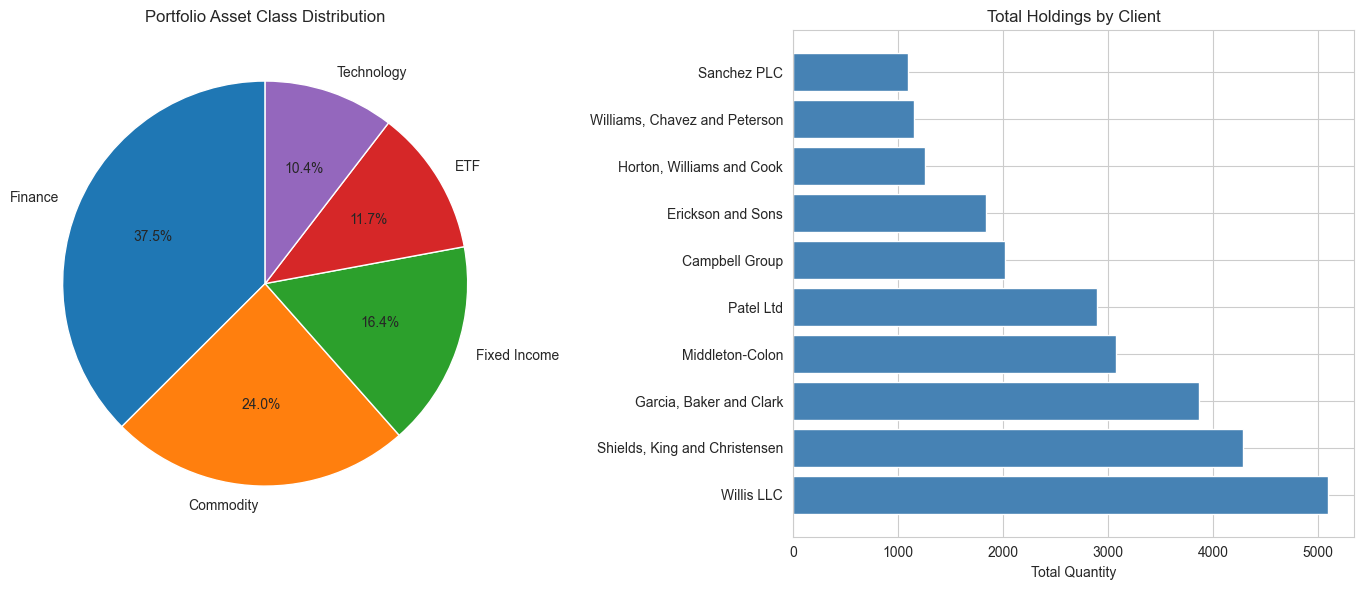


Visualization complete!


In [8]:
## 4. Portfolio Visualizations

# Asset allocation pie chart
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Overall asset class distribution
asset_summary = latest_holdings.groupby('asset_class')['quantity'].sum().sort_values(ascending=False)
axes[0].pie(asset_summary.values, labels=asset_summary.index, autopct='%1.1f%%', startangle=90)
axes[0].set_title('Portfolio Asset Class Distribution')

# Holdings by client
client_holdings = latest_holdings.groupby('client_name')['quantity'].sum().sort_values(ascending=False)
axes[1].barh(client_holdings.index, client_holdings.values, color='steelblue')
axes[1].set_xlabel('Total Quantity')
axes[1].set_title('Total Holdings by Client')

plt.tight_layout()
plt.show()

print("\nVisualization complete!")

In [9]:
## 5. Trade Activity Analysis

# # DATABASE QUERY - COMMENTED OUT FOR NOW
# conn = get_db_connection()
# if conn:
#     trades_query = """
#     SELECT 
#         c.client_name,
#         i.ticker,
#         ct.trade_type,
#         ct.quantity,
#         ct.price,
#         (ct.quantity * ct.price) as trade_value,
#         ct.trade_date,
#         ct.status
#     FROM client_trades ct
#     JOIN clients c ON ct.client_id = c.client_id
#     JOIN instruments i ON ct.instrument_id = i.instrument_id
#     WHERE ct.trade_date >= CURRENT_DATE - INTERVAL '30 days'
#     ORDER BY ct.trade_date DESC
#     """
#     
#     trades_df = pd.read_sql(trades_query, conn)
#     conn.close()

# USING FAKE DATA
trades_data = []
for _ in range(20):
    client = np.random.choice(clients)
    instrument = np.random.choice(instruments)
    quantity = np.random.randint(10, 500)
    price = np.random.uniform(50, 500)
    trade_date = datetime.now().date() - timedelta(days=np.random.randint(0, 30))
    
    trades_data.append({
        'client_name': client['client_name'],
        'ticker': instrument['ticker'],
        'trade_type': np.random.choice(['BUY', 'SELL']),
        'quantity': quantity,
        'price': price,
        'trade_value': quantity * price,
        'trade_date': trade_date,
        'status': np.random.choice(['PENDING', 'APPROVED', 'REJECTED', 'EXECUTED'], p=[0.1, 0.3, 0.1, 0.5])
    })

trades_df = pd.DataFrame(trades_data)

print("Recent Trade Activity (Last 30 Days):")
print(f"Total Trades: {len(trades_df)}")

# Trade statistics
print("\nTrade Summary by Status:")
print(trades_df['status'].value_counts())

print("\nTrade Summary by Type:")
print(trades_df.groupby('trade_type')['trade_value'].agg(['count', 'sum']).rename(columns={'count': 'Count', 'sum': 'Total Value'}))

print("\nTop 10 Trades:")
print(trades_df.nlargest(10, 'trade_value')[['client_name', 'ticker', 'trade_type', 'quantity', 'trade_date', 'status']])

Recent Trade Activity (Last 30 Days):
Total Trades: 20

Trade Summary by Status:
status
EXECUTED    12
APPROVED     4
PENDING      3
REJECTED     1
Name: count, dtype: int64

Trade Summary by Type:
            Count   Total Value
trade_type                     
BUY             6  4.932289e+05
SELL           14  1.193520e+06

Top 10 Trades:
                      client_name ticker trade_type  quantity  trade_date  \
8         Garcia, Baker and Clark    VTI       SELL       443  2026-09-09   
12      Horton, Williams and Cook    BND       SELL       429  2026-09-19   
14                Middleton-Colon    VTI       SELL       493  2026-10-08   
6   Williams, Chavez and Peterson   AMZN       SELL       412  2026-09-20   
15  Williams, Chavez and Peterson    BND        BUY       393  2026-10-06   
4                      Willis LLC   AAPL       SELL       264  2026-10-04   
2   Shields, King and Christensen    GLD        BUY       494  2026-10-08   
7   Williams, Chavez and Peterson    VTI  

In [10]:
## 6. Key Performance Metrics Summary

# # DATABASE QUERIES - COMMENTED OUT FOR NOW
# conn = get_db_connection()
# if conn:
#     # Portfolio metrics
#     metrics_data = {
#         'Total Clients': [holdings_df['client_name'].nunique()],
#         'Total Holdings': [len(latest_holdings)],
#         'Unique Instruments': [latest_holdings['ticker'].nunique()],
#         'Asset Classes': [latest_holdings['asset_class'].nunique()],
#         'Model Portfolios': [model_perf['model_portfolio_id'].nunique() if len(model_perf) > 0 else 0],
#     }
#     
#     metrics_df = pd.DataFrame(metrics_data)
#     print("Portfolio Overview Metrics:")
#     print(metrics_df)
#     
#     # Subscription status
#     subs_query = """
#     SELECT 
#         status,
#         COUNT(*) as count
#     FROM client_subscriptions
#     GROUP BY status
#     """
#     
#     subs = pd.read_sql(subs_query, conn)
#     print("\nSubscription Status:")
#     print(subs)
#     
#     conn.close()

# USING FAKE DATA
metrics_data = {
    'Total Clients': [holdings_df['client_name'].nunique()],
    'Total Holdings': [len(latest_holdings)],
    'Unique Instruments': [latest_holdings['ticker'].nunique()],
    'Asset Classes': [latest_holdings['asset_class'].nunique()],
    'Model Portfolios': [model_perf['model_portfolio_id'].nunique() if len(model_perf) > 0 else 0],
}

metrics_df = pd.DataFrame(metrics_data)
print("Portfolio Overview Metrics:")
print(metrics_df)

# Fake subscription status
subs = pd.DataFrame({
    'status': ['ACTIVE', 'PAUSED', 'ENDED'],
    'count': [np.random.randint(8, 15), np.random.randint(2, 5), np.random.randint(1, 3)]
})
print("\nSubscription Status:")
print(subs)

print("\n=== Analytics Summary Complete ===")
print(f"Generated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

Portfolio Overview Metrics:
   Total Clients  Total Holdings  Unique Instruments  Asset Classes  \
0             10              52                  10              5   

   Model Portfolios  
0                 3  

Subscription Status:
   status  count
0  ACTIVE      8
1  PAUSED      3
2   ENDED      1

=== Analytics Summary Complete ===
Generated: 2026-10-08 15:50:57



TOP 5 GAINERS (by price change %)
        min_price  max_price  price_change  price_change_pct  num_trades  \
ticker                                                                     
AAPL        66.60     411.41        344.81            517.73           3   
VTI        167.37     466.11        298.74            178.49           4   
JPM        162.71     334.01        171.30            105.28           2   
QQQ        161.09     298.80        137.71             85.49           2   
AMZN       232.03     370.02        137.99             59.47           2   

        total_quantity  
ticker                  
AAPL               923  
VTI               1431  
JPM                657  
QQQ                230  
AMZN               573  

TOP 5 LOSERS (by price change %)
        min_price  max_price  price_change  price_change_pct  num_trades  \
ticker                                                                     
AMZN       232.03     370.02        137.99             59.47           

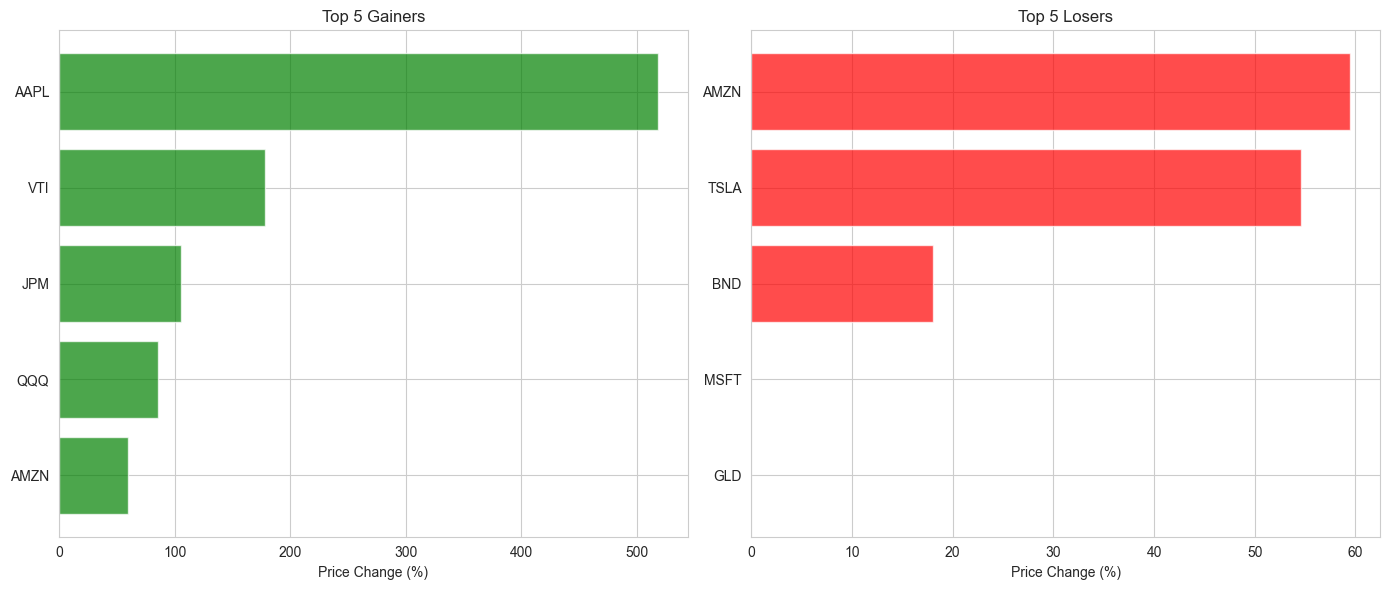


Instrument Performance Summary Complete!


In [11]:
## 7. Top 5 Gainers and Losers by Instrument

# Calculate instrument performance metrics
instrument_performance = trades_df.groupby('ticker').agg({
    'price': ['min', 'max', 'mean', 'count'],
    'quantity': 'sum',
    'trade_value': 'sum'
}).round(2)

instrument_performance.columns = ['min_price', 'max_price', 'avg_price', 'num_trades', 'total_quantity', 'total_value']
instrument_performance['price_change'] = (instrument_performance['max_price'] - instrument_performance['min_price']).round(2)
instrument_performance['price_change_pct'] = ((instrument_performance['price_change'] / instrument_performance['min_price']) * 100).round(2)

# Sort by price change percentage to get gainers and losers
instrument_performance_sorted = instrument_performance.sort_values('price_change_pct', ascending=False)

print("\n" + "="*80)
print("TOP 5 GAINERS (by price change %)")
print("="*80)
gainers = instrument_performance_sorted.head(5)[['min_price', 'max_price', 'price_change', 'price_change_pct', 'num_trades', 'total_quantity']]
print(gainers)

print("\n" + "="*80)
print("TOP 5 LOSERS (by price change %)")
print("="*80)
losers = instrument_performance_sorted.tail(5)[['min_price', 'max_price', 'price_change', 'price_change_pct', 'num_trades', 'total_quantity']]
print(losers)

# Visualize gainers vs losers
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Gainers chart
gainers_data = instrument_performance_sorted.head(5).sort_values('price_change_pct')
axes[0].barh(gainers_data.index, gainers_data['price_change_pct'], color='green', alpha=0.7)
axes[0].set_xlabel('Price Change (%)')
axes[0].set_title('Top 5 Gainers')
axes[0].axvline(x=0, color='black', linestyle='-', linewidth=0.5)

# Losers chart
losers_data = instrument_performance_sorted.tail(5).sort_values('price_change_pct')
axes[1].barh(losers_data.index, losers_data['price_change_pct'], color='red', alpha=0.7)
axes[1].set_xlabel('Price Change (%)')
axes[1].set_title('Top 5 Losers')
axes[1].axvline(x=0, color='black', linestyle='-', linewidth=0.5)

plt.tight_layout()
plt.show()

print("\nInstrument Performance Summary Complete!")


PORTFOLIO PERFORMANCE VS MAJOR INDEXES (1-Year Period)
Portfolio            | Final Return:   25.04% | Current Value: $ 126.04
S&P 500              | Final Return:   -6.22% | Current Value: $  94.06
DOW                  | Final Return:   75.90% | Current Value: $ 176.73
NASDAQ               | Final Return:  107.89% | Current Value: $ 211.48
Russell 2000         | Final Return:   35.47% | Current Value: $ 134.23


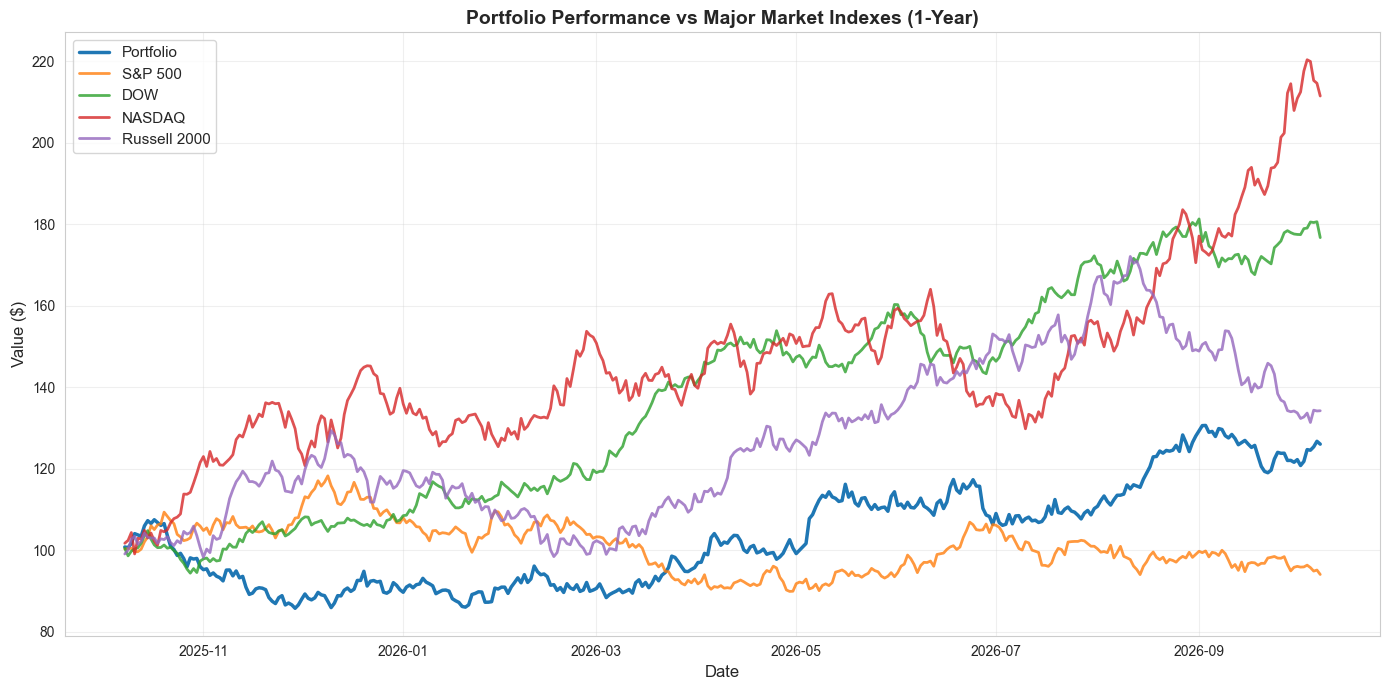


OUTPERFORMANCE ANALYSIS
vs S&P 500              | ✓ Outperforming      |  +31.27%
vs DOW                  | ✗ Underperforming    |  -50.86%
vs NASDAQ               | ✗ Underperforming    |  -82.85%
vs Russell 2000         | ✗ Underperforming    |  -10.43%

Portfolio Performance Analysis Complete!


In [12]:
## 8. Portfolio Performance vs Major Indexes

# Generate fake historical price data for portfolio and major indexes
date_range = pd.date_range(start='2025-10-08', end='2026-10-08', freq='D')

# Create fake performance data for portfolio and major indexes
# Starting values normalized to 100
np.random.seed(42)

# Generate random returns for each index/portfolio
portfolio_returns = np.random.normal(0.0005, 0.015, len(date_range))  # Small positive trend with volatility
sp500_returns = np.random.normal(0.0003, 0.012, len(date_range))       # Moderate returns
dow_returns = np.random.normal(0.0002, 0.011, len(date_range))         # Slight upward trend
nasdaq_returns = np.random.normal(0.0006, 0.018, len(date_range))      # Tech-heavy, more volatile
russell2k_returns = np.random.normal(0.0001, 0.016, len(date_range))   # Small-cap, volatile

# Calculate cumulative returns (normalized to 100 at start)
portfolio_prices = 100 * np.exp(np.cumsum(portfolio_returns))
sp500_prices = 100 * np.exp(np.cumsum(sp500_returns))
dow_prices = 100 * np.exp(np.cumsum(dow_returns))
nasdaq_prices = 100 * np.exp(np.cumsum(nasdaq_returns))
russell2k_prices = 100 * np.exp(np.cumsum(russell2k_returns))

# Create performance dataframe
performance_df = pd.DataFrame({
    'Date': date_range,
    'Portfolio': portfolio_prices,
    'S&P 500': sp500_prices,
    'DOW': dow_prices,
    'NASDAQ': nasdaq_prices,
    'Russell 2000': russell2k_prices
})

# Calculate final returns
print("\n" + "="*80)
print("PORTFOLIO PERFORMANCE VS MAJOR INDEXES (1-Year Period)")
print("="*80)
final_returns = {}
for col in ['Portfolio', 'S&P 500', 'DOW', 'NASDAQ', 'Russell 2000']:
    ret = ((performance_df[col].iloc[-1] - performance_df[col].iloc[0]) / performance_df[col].iloc[0] * 100)
    final_returns[col] = ret
    print(f"{col:20} | Final Return: {ret:7.2f}% | Current Value: ${performance_df[col].iloc[-1]:7.2f}")

# Create comparison chart
plt.figure(figsize=(14, 7))
plt.plot(performance_df['Date'], performance_df['Portfolio'], label='Portfolio', linewidth=2.5, color='#1f77b4')
plt.plot(performance_df['Date'], performance_df['S&P 500'], label='S&P 500', linewidth=2, alpha=0.8, color='#ff7f0e')
plt.plot(performance_df['Date'], performance_df['DOW'], label='DOW', linewidth=2, alpha=0.8, color='#2ca02c')
plt.plot(performance_df['Date'], performance_df['NASDAQ'], label='NASDAQ', linewidth=2, alpha=0.8, color='#d62728')
plt.plot(performance_df['Date'], performance_df['Russell 2000'], label='Russell 2000', linewidth=2, alpha=0.8, color='#9467bd')

plt.xlabel('Date', fontsize=12)
plt.ylabel('Value ($)', fontsize=12)
plt.title('Portfolio Performance vs Major Market Indexes (1-Year)', fontsize=14, fontweight='bold')
plt.legend(loc='upper left', fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Outperformance vs benchmarks
print("\n" + "="*80)
print("OUTPERFORMANCE ANALYSIS")
print("="*80)
portfolio_return = final_returns['Portfolio']
for benchmark in ['S&P 500', 'DOW', 'NASDAQ', 'Russell 2000']:
    outperformance = portfolio_return - final_returns[benchmark]
    status = "✓ Outperforming" if outperformance > 0 else "✗ Underperforming"
    print(f"vs {benchmark:20} | {status:20} | {outperformance:+7.2f}%")

print("\nPortfolio Performance Analysis Complete!")